# 01: Clinical Data Preprocessing

Preprocesses TCGA clinical data for LUAD vs LUSC binary classification.

**Pipeline**
| Step | Action |
|------|--------|
| 1 | Load raw clinical CSV (99 columns) |
| 2 | Load labels and create target `y` |
| 3 | Select candidate clinical columns |
| 4 | Inspect and visualise missing values |
| 5 | Drop columns with >50% missingness |
| 6 | Impute remaining missing values |
| 7 | One-hot encode categorical columns |
| 8 | ExtraTreesClassifier feature selection (train set only) → top features (data-driven cutoff) |
| 9 | Save final feature matrix |

> **Output:** `Data/clinical_features.csv`

## Imports and configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import StratifiedShuffleSplit
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Paths
import os

BASE_DIR = Path(
    os.environ.get("FUSION_REPO_DIR", str(Path.cwd()))
).expanduser().resolve()

if BASE_DIR.name in {"Preprocessing", "Training"}:
    BASE_DIR = BASE_DIR.parent

if not (BASE_DIR / "Training" / "07_controlled_early_late_fusion.ipynb").is_file():
    raise RuntimeError(
        "Start Jupyter from the repository directory or set FUSION_REPO_DIR."
    )
DATA_DIR = Path(
    os.environ.get("FUSION_DATA_DIR", str(BASE_DIR / "Data"))
).expanduser().resolve()

OUT_DIR = BASE_DIR / "Preprocessing"
FIG_DIR       = OUT_DIR / 'Figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

CLINICAL_RAW  = DATA_DIR / 'clinical_cleaned.csv'
LABELS_PATH = DATA_DIR / "multiomics_labels.tsv"
SPLIT_PATH    = DATA_DIR / 'train_test_split.csv'
OUT_PATH      = OUT_DIR  / 'clinical_features.csv'
SELECTOR_PATH = OUT_DIR  / 'clinical_selected_features.txt'

In [3]:
# Config
RANDOM_STATE = 42
IMPORTANCE_THRESH = 0.95   # Retain features until this fraction of cumulative importance is covered
MISS_THRESH  = 0.50        # Drop columns with > 50% missing values

print('Imports OK')
print(f'Clinical raw        : {CLINICAL_RAW}')
print(f'Output path         : {OUT_PATH}')
print(f'Importance threshold: {IMPORTANCE_THRESH:.0%} cumulative')

Imports OK
Clinical raw        : /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Data/clinical_cleaned.csv
Output path         : /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/clinical_features.csv
Importance threshold: 95% cumulative


## Load raw clinical data

In [4]:
df_raw = pd.read_csv(CLINICAL_RAW)

# Normalise patient ID to TCGA-XX-XXXX format and set as index
id_col = 'submitter_id' if 'submitter_id' in df_raw.columns else df_raw.columns[0]
df_raw[id_col] = df_raw[id_col].str.strip().str.upper().str[:12]
df_raw = df_raw.drop_duplicates(subset=id_col).set_index(id_col)
df_raw.index.name = 'patient_id'

print(f'Raw shape       : {df_raw.shape}')
print(f'Unique patients : {df_raw.shape[0]}')
print(f'\nFirst 5 columns : {df_raw.columns[:5].tolist()}')
df_raw.head(3)

Raw shape       : (1089, 98)
Unique patients : 1089

First 5 columns : ['project', 'morphology', 'days_to_diagnosis', 'created_datetime', 'tissue_or_organ_of_origin']


,project,morphology,days_to_diagnosis,created_datetime,tissue_or_organ_of_origin,age_at_diagnosis,primary_diagnosis,classification_of_tumor,tumor_of_origin,updated_datetime,...,treatments_radiation_treatment_intent_type,treatments_radiation_treatment_dose_units,treatments_radiation_course_number,treatments_radiation_prescribed_dose_units,treatments_radiation_route_of_administration,treatments_radiation_number_of_cycles,treatments_radiation_prescribed_dose,treatments_radiation_initial_disease_status,bcr_patient_barcode,patient_id
patient_id,,,,,,,,,,,,,,,,,,,,,
TCGA-MP-A4SV,TCGA-LUAD,8140/3,0.0,NaN,"Lower lobe, lung",24516.0,"Adenocarcinoma, NOS",primary,NaN,2025-10-24T10:05:51.248574-05:00,...,Adjuvant,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TCGA-MP-A4SV,TCGA-MP-A4SV
TCGA-55-8621,TCGA-LUAD,8140/3,0.0,NaN,"Lower lobe, lung",27485.0,"Adenocarcinoma, NOS",primary,NaN,2025-10-24T10:05:51.248574-05:00,...,Adjuvant,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TCGA-55-8621,TCGA-55-8621
TCGA-MN-A4N1,TCGA-LUAD,8140/3,0.0,NaN,"Upper lobe, lung",21939.0,"Adenocarcinoma, NOS",primary,NaN,2025-10-24T10:05:51.248574-05:00,...,Adjuvant,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TCGA-MN-A4N1,TCGA-MN-A4N1


## 2. Load labels and create target `y`

Labels are loaded from the pre-built `labels.csv` (patient_id, label) where label is 0=LUAD, 1=LUSC.
We intersect with the clinical index so only patients present in both are retained.

In [5]:
df_labels = pd.read_csv(LABELS_PATH, sep='\t', index_col='patient_id')
df_labels.index = df_labels.index.str.strip().str.upper().str[:12]

labels = df_labels['subtype_simple'].map({'LUAD': 0, 'LUSC': 1})

# Intersect patients
common_ids = df_raw.index.intersection(labels.index)
df_raw     = df_raw.loc[common_ids]
y          = labels.loc[common_ids]

print(f'Patients after intersection : {len(common_ids)}')
print(f'Class distribution          :')
print(y.value_counts().rename({0: 'LUAD', 1: 'LUSC'}).to_string())

Patients after intersection : 831
Class distribution          :
subtype_simple
LUAD    459
LUSC    372


## 3. Load train/test split indices

Feature selection (ExtraTreesClassifier) must be fitted on training patients only to prevent data leakage.
The split is loaded from the pre-saved `train_test_split.csv` so all modality notebooks use identical splits.

If the split file does not yet exist it is created here and saved for all subsequent notebooks to reuse.

In [6]:
if SPLIT_PATH.exists():
    split_df   = pd.read_csv(SPLIT_PATH, index_col='patient_id')
    # Keep only patients that are in the current clinical cohort
    split_df   = split_df.loc[split_df.index.intersection(common_ids)]
    train_ids  = split_df[split_df['split'] == 'train'].index
    test_ids   = split_df[split_df['split'] == 'test'].index
    print(f'Loaded existing split, train: {len(train_ids)}, test: {len(test_ids)}')
else:
    # Create a 70/30 stratified split and save it
    sss = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
    idx = np.arange(len(common_ids))
    train_pos, test_pos = next(sss.split(idx, y.values))

    train_ids = common_ids[train_pos]
    test_ids  = common_ids[test_pos]

    split_df = pd.DataFrame(
        {'split': ['train'] * len(train_ids) + ['test'] * len(test_ids)},
        index=list(train_ids) + list(test_ids)
    )
    split_df.index.name = 'patient_id'
    split_df.to_csv(SPLIT_PATH)
    print(f'Created & saved split, train: {len(train_ids)}, test: {len(test_ids)}')

print(f'Train class dist: {y.loc[train_ids].value_counts().to_dict()}')
print(f'Test  class dist: {y.loc[test_ids].value_counts().to_dict()}')

Loaded existing split, train: 581, test: 250
Train class dist: {0: 321, 1: 260}
Test  class dist: {0: 138, 1: 112}


## 4. Select candidate clinical columns

From the 99 raw columns we retain those with clinical relevance for lung cancer subtyping:
demographics, staging, tumour characteristics, smoking history, and treatment variables.
Identifier columns and the target variable are excluded.

In [7]:
# Columns to always exclude  -  identifiers, target, timestamps
EXCLUDE = {
    'project', 'label', 'bcr_patient_barcode', 'created_datetime',
    'updated_datetime', 'diagnosis_id', 'exposure_id', 'demographic_id',
    'treatments_pharmaceutical_treatment_id',
    'treatments_radiation_treatment_id',
    'primary_diagnosis', 'morphology', 'icd_10_code',
    'tissue_or_organ_of_origin', 'site_of_resection_or_biopsy',
    'vital_status', 'days_to_death', 'days_to_last_follow_up',
    'last_known_disease_status', 'days_to_last_known_disease_status',
    'days_to_recurrence', 'progression_or_recurrence',
    'follow_ups_disease_response',
}

# Candidate columns  -  all clinically meaningful variables
CANDIDATES = [
    # Demographics
    'age_at_diagnosis', 'age_at_index', 'gender', 'race', 'ethnicity',
    'year_of_birth', 'year_of_diagnosis',
    # Vital status & follow-up
    'vital_status', 'days_to_death', 'days_to_last_follow_up',
    'last_known_disease_status', 'days_to_last_known_disease_status',
    # Prior history
    'prior_malignancy', 'prior_treatment', 'synchronous_malignancy',
    # Pathologic staging
    'ajcc_pathologic_stage', 'ajcc_pathologic_t', 'ajcc_pathologic_n',
    'ajcc_pathologic_m', 'ajcc_staging_system_edition',
    # Tumour characteristics
    'primary_diagnosis', 'morphology', 'icd_10_code', 'tumor_grade',
    'tissue_or_organ_of_origin', 'site_of_resection_or_biopsy',
    'laterality', 'residual_disease',
    # Smoking & alcohol exposure
    'tobacco_smoking_status', 'pack_years_smoked', 'cigarettes_per_day',
    'tobacco_smoking_onset_year', 'tobacco_smoking_quit_year',
    'alcohol_history', 'alcohol_intensity',
    # Treatment
    'treatments_pharmaceutical_treatment_or_therapy',
    'treatments_pharmaceutical_treatment_type',
    'treatments_pharmaceutical_treatment_intent_type',
    'treatments_pharmaceutical_treatment_outcome',
    'treatments_radiation_treatment_or_therapy',
    'treatments_radiation_treatment_type',
    'treatments_radiation_treatment_intent_type',
    # Progression
    'progression_or_recurrence', 'days_to_recurrence',
    'follow_ups_disease_response',
]

available = [c for c in CANDIDATES if c in df_raw.columns and c not in EXCLUDE]
missing   = [c for c in CANDIDATES if c not in df_raw.columns]

df_clin = df_raw[available].copy()

print(f'Candidates requested : {len(CANDIDATES)}')
print(f'Found in file        : {len(available)}')
print(f'Not in file (skipped): {missing}')
print(f'Working shape        : {df_clin.shape}')

Candidates requested : 45
Found in file        : 32
Not in file (skipped): []
Working shape        : (831, 32)


## 5. Inspect and visualise missing values

Missing value fraction per column:
year_of_birth                                      1.000000
tumor_grade                                        1.000000
cigarettes_per_day                                 1.000000
alcohol_history                                    1.000000
alcohol_intensity                                  1.000000
treatments_pharmaceutical_treatment_outcome        0.978339
tobacco_smoking_quit_year                          0.459687
tobacco_smoking_onset_year                         0.407942
treatments_pharmaceutical_treatment_intent_type    0.348977
treatments_pharmaceutical_treatment_or_therapy     0.342960
treatments_pharmaceutical_treatment_type           0.342960
pack_years_smoked                                  0.244284
residual_disease                                   0.227437
treatments_radiation_treatment_intent_type         0.140794
age_at_diagnosis                                   0.066185
ajcc_staging_system_edition                        0.046931
age_a

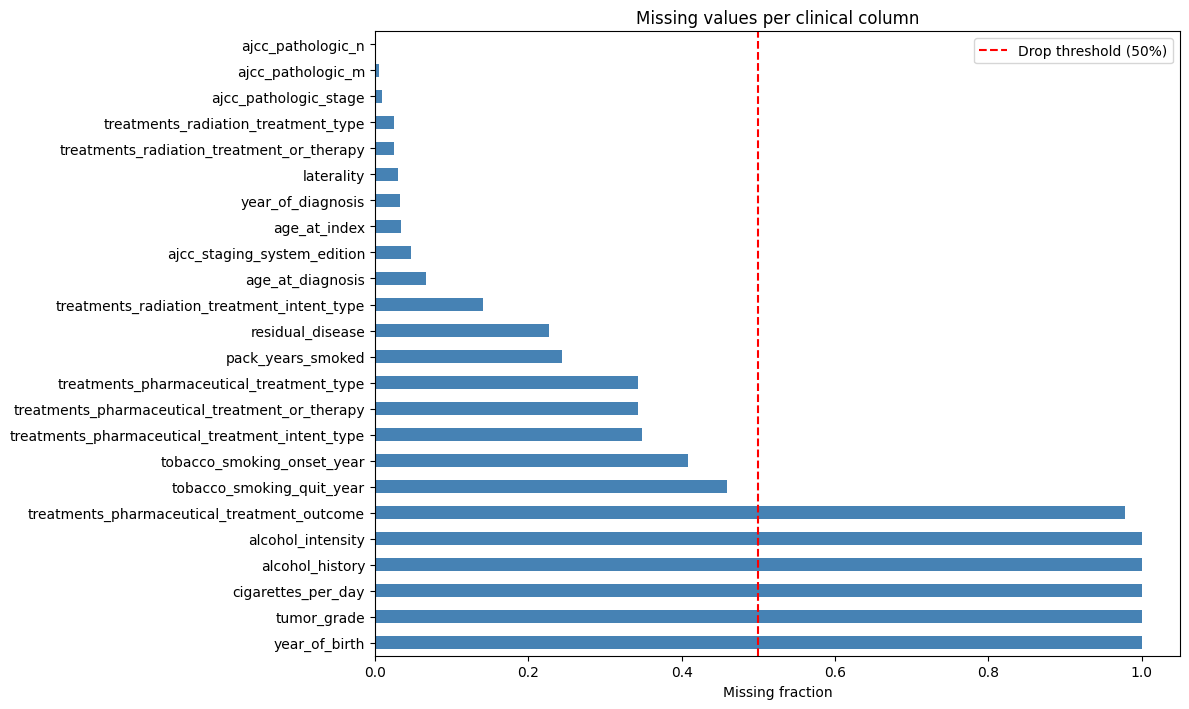

Figure saved to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/Figures/clinical_missing_values.png


In [8]:
miss_frac = df_clin.isnull().mean().sort_values(ascending=False)
print('Missing value fraction per column:')
print(miss_frac[miss_frac > 0].to_string())

fig, ax = plt.subplots(figsize=(12, max(4, len(miss_frac[miss_frac > 0]) * 0.3)))
miss_frac[miss_frac > 0].plot(kind='barh', ax=ax, color='steelblue')
ax.axvline(MISS_THRESH, color='red', linestyle='--', label=f'Drop threshold ({MISS_THRESH:.0%})')
ax.set_xlabel('Missing fraction')
ax.set_title('Missing values per clinical column')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'clinical_missing_values.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved to {FIG_DIR}/clinical_missing_values.png')

## 6. Drop columns with >50% missing values

In [9]:
cols_to_drop = miss_frac[miss_frac > MISS_THRESH].index.tolist()
df_clin      = df_clin.drop(columns=cols_to_drop)

print(f'Columns dropped (>{MISS_THRESH:.0%} missing) : {cols_to_drop}')
print(f'Shape after dropping                        : {df_clin.shape}')

Columns dropped (>50% missing) : ['year_of_birth', 'tumor_grade', 'cigarettes_per_day', 'alcohol_history', 'alcohol_intensity', 'treatments_pharmaceutical_treatment_outcome']
Shape after dropping                        : (831, 26)


## 7. Impute remaining missing values

- **Numeric columns**: imputed with the column median (robust to skew)
- **Categorical columns**: imputed with the column mode (most frequent value)

In [10]:
num_cols = df_clin.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_clin.select_dtypes(include=['object', 'category']).columns.tolist()

# Impute numeric with median
for col in num_cols:
    median_val = df_clin.loc[train_ids, col].median()
    df_clin[col] = df_clin[col].fillna(median_val)

# Impute categorical with mode
for col in cat_cols:
    mode_val = df_clin.loc[train_ids, col].mode()
    fill_val = mode_val.iloc[0] if len(mode_val) > 0 else 'unknown'
    df_clin[col] = df_clin[col].fillna(fill_val)

assert df_clin.isnull().sum().sum() == 0, 'Imputation incomplete  -  NaNs still present'
print(f'Numeric columns  : {len(num_cols)}')
print(f'Categorical cols : {len(cat_cols)}')
print(f'Total NaNs after imputation: {df_clin.isnull().sum().sum()}')

Numeric columns  : 6
Categorical cols : 20
Total NaNs after imputation: 0


## 8. One-hot encode categorical columns

All remaining categorical columns are one-hot encoded using `pd.get_dummies`.
Boolean columns created by dummies are cast to `int` for downstream compatibility.

In [11]:
df_encoded = pd.get_dummies(df_clin, columns=cat_cols, drop_first=True)

# Cast bool columns to int
bool_cols = df_encoded.select_dtypes(include='bool').columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

print(f'Shape before encoding : {df_clin.shape}')
print(f'Shape after encoding  : {df_encoded.shape}')
print(f'Example new columns   : {df_encoded.columns[-5:].tolist()}')

Shape before encoding : (831, 26)
Shape after encoding  : (831, 81)
Example new columns   : ['treatments_radiation_treatment_intent_type_NA;Palliative', 'treatments_radiation_treatment_intent_type_Not Reported', 'treatments_radiation_treatment_intent_type_Palliative', 'treatments_radiation_treatment_intent_type_Palliative;Adjuvant', 'treatments_radiation_treatment_intent_type_Palliative;NA']


## 9. Feature selection: ExtraTreesClassifier (train set only)

An ExtraTreesClassifier is fitted **exclusively on training patients** to rank features by importance.
The top features (data-driven cutoff) are selected and the importance ranking is visualised.
The same feature columns are then applied to the full dataset (train + test) without refitting.

In [12]:
# Split encoded matrix into train / test
X_train = df_encoded.loc[df_encoded.index.intersection(train_ids)]
X_test  = df_encoded.loc[df_encoded.index.intersection(test_ids)]
y_train = y.loc[X_train.index]

print(f'X_train shape : {X_train.shape}')
print(f'X_test shape  : {X_test.shape}')

X_train shape : (581, 81)
X_test shape  : (250, 81)


In [13]:
# Fit ExtraTreesClassifier on training set only
etc = ExtraTreesClassifier(
    n_estimators=500,
    max_features='sqrt',
    random_state=RANDOM_STATE,
    n_jobs=-1
)
etc.fit(X_train, y_train)

,n_estimators,500
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [14]:
# Rank all features by importance
importances = pd.Series(etc.feature_importances_, index=df_encoded.columns)
importances = importances.sort_values(ascending=False)

# Select features by cumulative importance threshold (data-driven cutoff)
cumulative   = importances.cumsum() / importances.sum()
n_selected   = int((cumulative < IMPORTANCE_THRESH).sum()) + 1  # first index that meets threshold
top_features = importances.iloc[:n_selected].index.tolist()
coverage     = cumulative.iloc[n_selected - 1]

print(f'\nFeatures selected at {IMPORTANCE_THRESH:.0%} cumulative importance: {n_selected}')
print(f'Actual coverage                                               : {coverage:.2%}')
print(f'\nSelected features:')
for i, (feat, imp) in enumerate(importances.iloc[:n_selected].items(), 1):
    print(f'  {i:>2}. {feat:<55} importance={imp:.4f}')


Features selected at 95% cumulative importance: 44
Actual coverage                                               : 95.06%

Selected features:
   1. gender_male                                             importance=0.0647
   2. age_at_diagnosis                                        importance=0.0607
   3. pack_years_smoked                                       importance=0.0602
   4. age_at_index                                            importance=0.0589
   5. tobacco_smoking_onset_year                              importance=0.0529
   6. tobacco_smoking_quit_year                               importance=0.0486
   7. year_of_diagnosis                                       importance=0.0483
   8. laterality_Right                                        importance=0.0335
   9. tobacco_smoking_status_Lifelong Non-Smoker              importance=0.0307
  10. tobacco_smoking_status_Current Reformed Smoker for > 15 yrs importance=0.0275
  11. ajcc_pathologic_m_MX                           

### 9a. Visualize feature importances

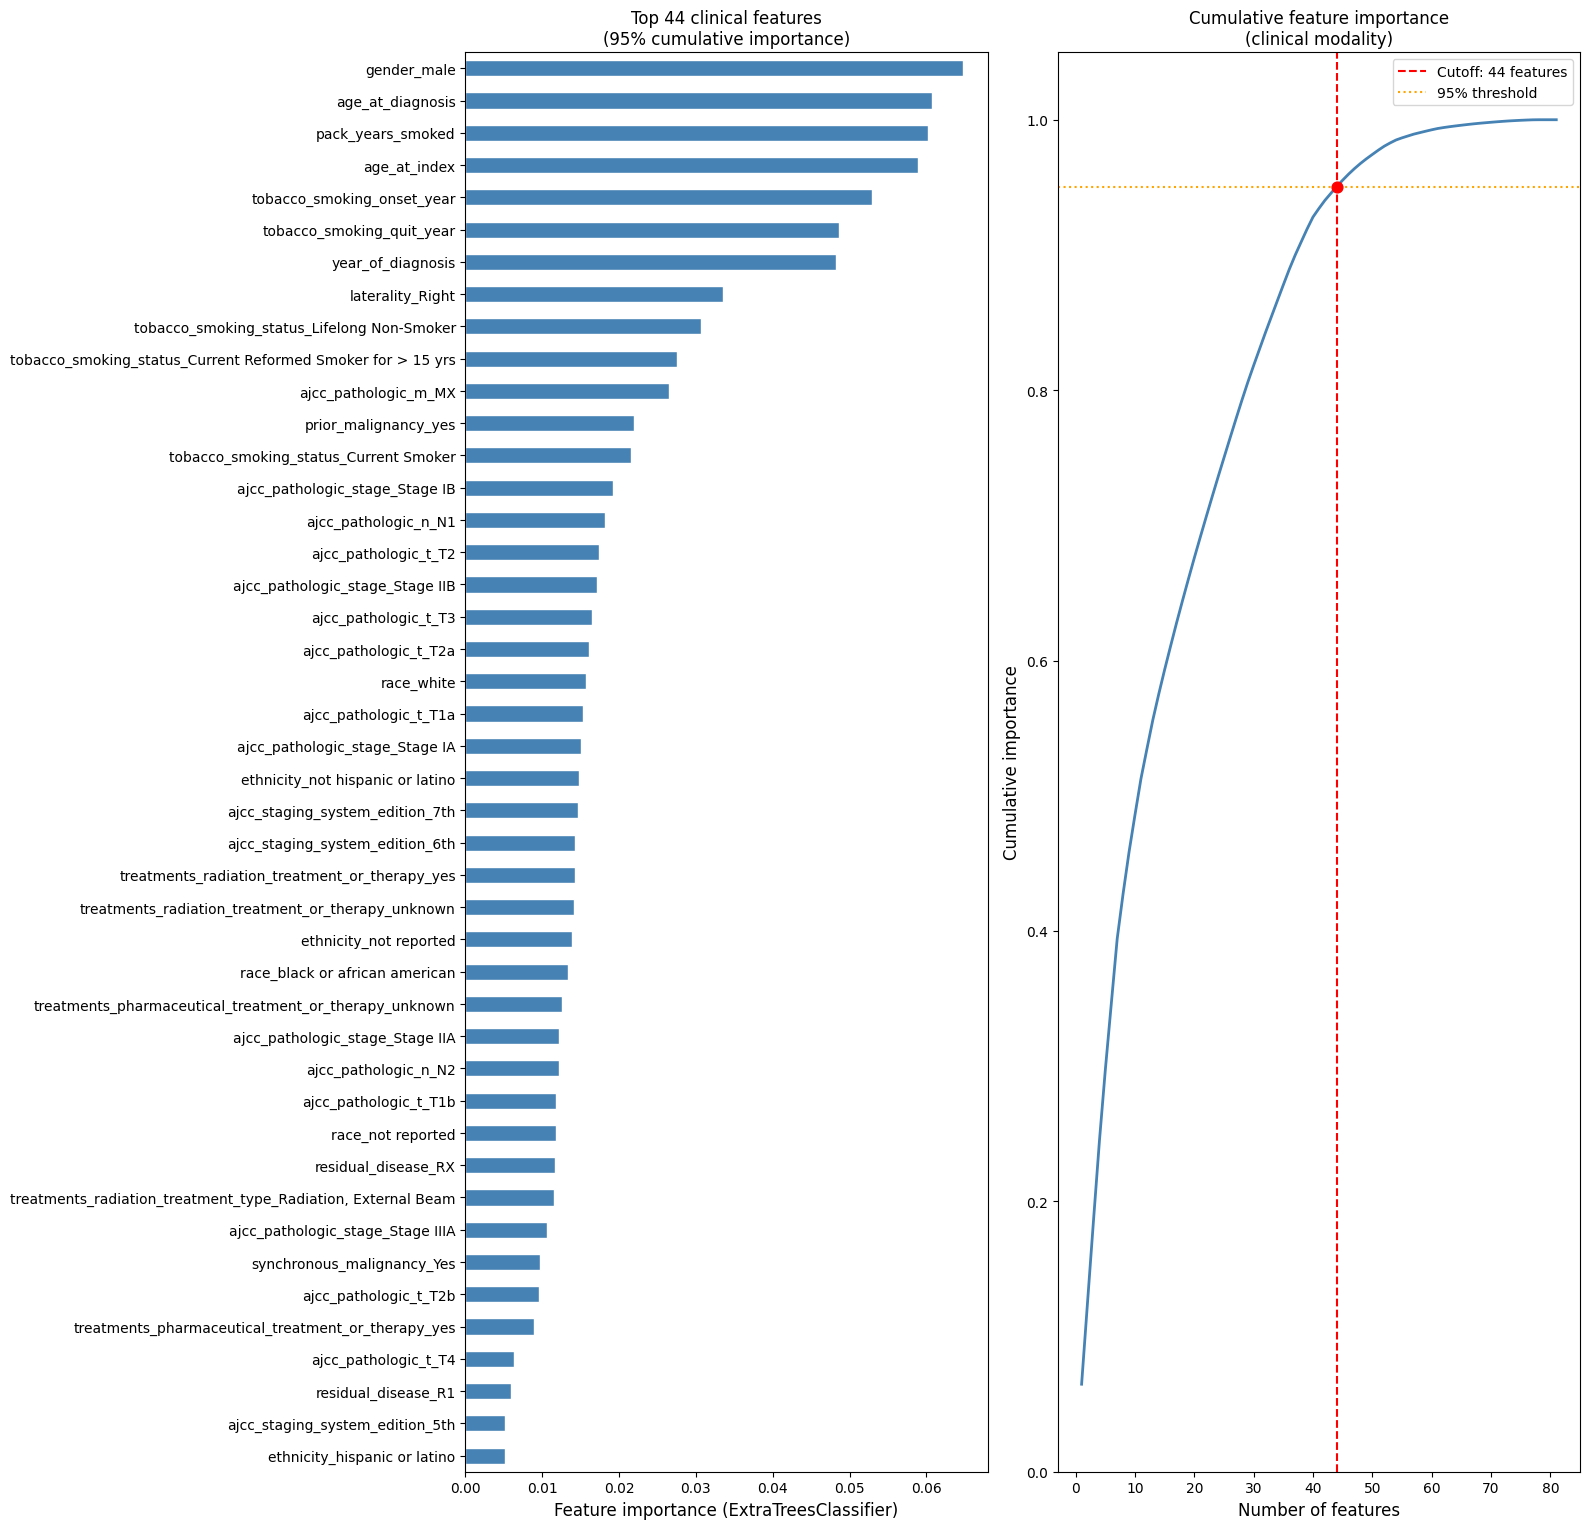

Figure saved to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/Figures/clinical_feature_importance.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, max(4, n_selected * 0.35)))

# Left: bar chart of selected feature importances
ax = axes[0]
importances.iloc[:n_selected].sort_values().plot(
    kind='barh', ax=ax, color='steelblue', edgecolor='white'
)
ax.set_xlabel('Feature importance (ExtraTreesClassifier)', fontsize=12)
ax.set_title(f'Top {n_selected} clinical features\n({IMPORTANCE_THRESH:.0%} cumulative importance)', fontsize=12)

# Right: cumulative importance curve with cutoff
ax2 = axes[1]
ax2.plot(range(1, len(cumulative) + 1), cumulative.values, color='steelblue', linewidth=2)
ax2.axvline(n_selected, color='red', linestyle='--', linewidth=1.5,
            label=f'Cutoff: {n_selected} features')
ax2.axhline(IMPORTANCE_THRESH, color='orange', linestyle=':', linewidth=1.5,
            label=f'{IMPORTANCE_THRESH:.0%} threshold')
ax2.scatter([n_selected], [coverage], color='red', zorder=5, s=60)
ax2.set_xlabel('Number of features', fontsize=12)
ax2.set_ylabel('Cumulative importance', fontsize=12)
ax2.set_title('Cumulative feature importance\n(clinical modality)', fontsize=12)
ax2.legend(fontsize=10)
ax2.set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig(FIG_DIR / 'clinical_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved to {FIG_DIR}/clinical_feature_importance.png')

In [16]:
# Summary of coverage
remaining_features = len(importances) - n_selected
remaining_importance = 1 - coverage
print(f'Selected : {n_selected} features  to  {coverage:.2%} of total importance')
print(f'Dropped  : {remaining_features} features  to  {remaining_importance:.2%} of total importance (noise tail)')

Selected : 44 features  to  95.06% of total importance
Dropped  : 37 features  to  4.94% of total importance (noise tail)


## 10. Apply selection to full cohort and save

In [17]:
# Apply the features selected from training to the full dataset
df_final = df_encoded[top_features].copy()

# Save feature matrix
df_final.to_csv(OUT_PATH)
print(f'Saved feature matrix to {OUT_PATH}')
print(f'Shape                : {df_final.shape}  (patients × features)')

# Save selected feature names for reference
with open(SELECTOR_PATH, 'w') as f:
    f.write('\n'.join(top_features))
print(f'Feature names saved to {SELECTOR_PATH}')

Saved feature matrix to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/clinical_features.csv
Shape                : (831, 44)  (patients × features)
Feature names saved to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/clinical_selected_features.txt


In [18]:
# At the end of cell 4, after filtering candidates, add:
print(f'Candidate columns found: {len(available)}')

Candidate columns found: 32


In [19]:
df_encoded.shape[1]

81

## Summary

| Step | Result |
|------|--------|
| Raw columns | 99 |
| Candidate clinical columns | 32 |
| After dropping >50% missing | 26 |
| After one-hot encoding | 81 |
| **Final selected features** | **44 (95% cumulative importance)** |
| Output file | `Data/clinical_features.csv` |
| Feature selection method | ExtraTreesClassifier, 500 trees, 95% cumulative importance threshold |
| Leakage prevention | Imputation and feature selector fitted on train only |